# Exploración de datos — Galaxy Zoo: The Galaxy Challenge

Clasificador binario elíptica vs. espiral

**Fuente del dataset:** [Galaxy Zoo - The Galaxy Challenge (Kaggle)](https://www.kaggle.com/competitions/galaxy-zoo-the-galaxy-challenge/overview)

## Significado de las columnas segun Galaxy Zoo

El CSV `training_solutions_rev1.csv` no trae una clase discreta: trae **37 vote fractions**
(fracción de voluntarios de Galaxy Zoo 2 que respondió cada opción), correspondientes a
**11 preguntas jerárquicas** del árbol de decisión de GZ2. Se confirmó la correspondencia
exacta columna ↔ pregunta ↔ respuesta contra la **Tabla 2 de Willett et al. (2013)**,
*"Galaxy Zoo 2: detailed morphological classifications..."*

| ID | Columnas | Pregunta | Respuestas (en orden, .1 → .N) | Siguiente task |
|---|---|---|---|---|
| 1 | `Class1.1-3` | ¿Es suave y redondeada, sin señal de disco? | smooth / features-or-disk / star-or-artifact | 7 / 2 / — |
| 2 | `Class2.1-2` | ¿Podría ser un disco visto de canto (edge-on)? | yes / no | 9 / 3 |
| 3 | `Class3.1-2` | ¿Hay señal de barra en el centro? | bar / no bar | 4 / 4 |
| 4 | `Class4.1-2` | ¿Hay señal de patrón de brazos espirales? | spiral / no spiral | 10 / 5 |
| 5 | `Class5.1-4` | ¿Qué tan prominente es el bulbo central? | no bulge / just noticeable / obvious / dominant | 6 (todas) |
| 6 | `Class6.1-2` | ¿Hay algo extraño (odd)? | yes / no | 8 / fin |
| 7 | `Class7.1-3` | ¿Qué tan redondeada es? | completely round / in between / cigar-shaped | 6 (todas) |
| 8 | `Class8.1-7` | ¿Qué tipo de rareza? | ring / lens-or-arc / disturbed / irregular / other / merger / dust-lane | fin (todas) |
| 9 | `Class9.1-3` | ¿Bulbo al centro (visto de canto)? ¿Forma? | rounded / boxy / no bulge | 6 (todas) |
| 10 | `Class10.1-3` | ¿Qué tan cerrados son los brazos espirales? | tight / medium / loose | 11 (todas) |
| 11 | `Class11.1-6` | ¿Cuántos brazos espirales? | 1 / 2 / 3 / 4 / more than 4 / can't tell | 5 (todas) |

**Para el binario de esta fase** solo usamos Task 1:
- `Class1.1` (smooth) → proxy de **elíptica**
- `Class1.2` (features/disk) → proxy de **espiral**
- `Class1.3` (star/artifact) → se descarta, no es una galaxia

Regla de etiquetado limpio: **elíptica si `Class1.1 >= 0.8`, espiral si `Class1.2 >= 0.8`**,
descartar el resto (mismo umbral que Walmsley et al. 2022 para "vote fraction confiable").
Implementada en `src/data/labeling.py`


In [1]:
# importaciones sistemas
import sys
from pathlib import Path

# Referencia aotros archivos sin necesidad de instalar el paquete
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de librerias de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image


In [2]:
# configuracion de proyecto
from src.config import (
    TRAIN_SOLUTIONS_CSV,
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR,
    CLEAN_LABEL_THRESHOLD,
    RANDOM_SEED,
    TRAIN_FRAC,
    VAL_FRAC,
    TEST_FRAC,
    ELLIPTICAL_LABEL,
    SPIRAL_LABEL,
    AMBIGUOUS_LABEL,
)
from src.data.labeling import derive_binary_label

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option("display.max_columns", 40)

## Carga de `training_solutions_rev1.csv` e inspección general

In [3]:
df = pd.read_csv(TRAIN_SOLUTIONS_CSV)
print(f"shape: {df.shape}")
df.head()

shape: (61578, 38)


,GalaxyID,Class1.1,Class1.2,Class1.3,Class2.1,Class2.2,Class3.1,Class3.2,Class4.1,Class4.2,Class5.1,Class5.2,Class5.3,Class5.4,Class6.1,Class6.2,Class7.1,Class7.2,Class7.3,Class8.1,Class8.2,Class8.3,Class8.4,Class8.5,Class8.6,Class8.7,Class9.1,Class9.2,Class9.3,Class10.1,Class10.2,Class10.3,Class11.1,Class11.2,Class11.3,Class11.4,Class11.5,Class11.6
0,100008,0.383147,0.616853,0.000000,0.000000,0.616853,0.038452,0.578401,0.418398,0.198455,0.0,0.104752,0.512101,0.000000,0.054453,0.945547,0.201463,0.181684,0.000000,0.0,0.027227,0.000000,0.027227,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.279952,0.138445,0.000000,0.000000,0.092886,0.0,0.0,0.0,0.325512
1,100023,0.327001,0.663777,0.009222,0.031178,0.632599,0.467370,0.165229,0.591328,0.041271,0.0,0.236781,0.160941,0.234877,0.189149,0.810851,0.000000,0.135082,0.191919,0.0,0.000000,0.140353,0.000000,0.048796,0.000000,0.0,0.012414,0.0,0.018764,0.000000,0.131378,0.459950,0.000000,0.591328,0.0,0.0,0.0,0.000000
2,100053,0.765717,0.177352,0.056931,0.000000,0.177352,0.000000,0.177352,0.000000,0.177352,0.0,0.117790,0.059562,0.000000,0.000000,1.000000,0.000000,0.741864,0.023853,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000
3,100078,0.693377,0.238564,0.068059,0.000000,0.238564,0.109493,0.129071,0.189098,0.049466,0.0,0.000000,0.113284,0.125280,0.320398,0.679602,0.408599,0.284778,0.000000,0.0,0.000000,0.096119,0.096119,0.000000,0.128159,0.0,0.000000,0.0,0.000000,0.094549,0.000000,0.094549,0.189098,0.000000,0.0,0.0,0.0,0.000000
4,100090,0.933839,0.000000,0.066161,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.029383,0.970617,0.494587,0.439252,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.029383,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61578 entries, 0 to 61577
Data columns (total 38 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   GalaxyID   61578 non-null  int64  
 1   Class1.1   61578 non-null  float64
 2   Class1.2   61578 non-null  float64
 3   Class1.3   61578 non-null  float64
 4   Class2.1   61578 non-null  float64
 5   Class2.2   61578 non-null  float64
 6   Class3.1   61578 non-null  float64
 7   Class3.2   61578 non-null  float64
 8   Class4.1   61578 non-null  float64
 9   Class4.2   61578 non-null  float64
 10  Class5.1   61578 non-null  float64
 11  Class5.2   61578 non-null  float64
 12  Class5.3   61578 non-null  float64
 13  Class5.4   61578 non-null  float64
 14  Class6.1   61578 non-null  float64
 15  Class6.2   61578 non-null  float64
 16  Class7.1   61578 non-null  float64
 17  Class7.2   61578 non-null  float64
 18  Class7.3   61578 non-null  float64
 19  Class8.1   61578 non-null  float64
 20  Class8.2   61578 

In [5]:
# Nulos y duplicados
print("Valores nulos por columna (total):", df.isnull().sum().sum())
print("GalaxyID duplicados:", df['GalaxyID'].duplicated().sum())
df.describe().T

Valores nulos por columna (total): 0
GalaxyID duplicados: 0


,count,mean,std,min,25%,50%,75%,max
GalaxyID,61578.0,550179.708337,258724.130197,100008.0,327874.250000,551933.000000,773232.000000,999967.000000
Class1.1,61578.0,0.432526,0.283517,0.0,0.175812,0.416994,0.679182,1.000000
Class1.2,61578.0,0.542261,0.296429,0.0,0.280862,0.558754,0.811339,1.000000
Class1.3,61578.0,0.025213,0.037967,0.0,0.000000,0.014870,0.034325,0.935147
Class2.1,61578.0,0.106408,0.212505,0.0,0.000000,0.000000,0.085161,1.000000
Class2.2,61578.0,0.435854,0.301867,0.0,0.168490,0.394850,0.694615,1.000000
Class3.1,61578.0,0.102526,0.177301,0.0,0.000000,0.000000,0.134555,1.000000
Class3.2,61578.0,0.333328,0.247675,0.0,0.122592,0.289248,0.516800,1.000000
Class4.1,61578.0,0.215629,0.285502,0.0,0.000000,0.092987,0.330231,1.000000
Class4.2,61578.0,0.220224,0.179835,0.0,0.072656,0.183640,0.338920,0.957937


In [6]:
# Consistencia con las imágenes en disco
train_ids_csv = set(df['GalaxyID'])
train_files = list(TRAIN_IMAGES_DIR.glob('*.jpg'))
train_ids_disk = {int(p.stem) for p in train_files}

print(f"Filas en CSV:              {len(train_ids_csv)}")
print(f"Imagenes en {TRAIN_IMAGES_DIR.name}: {len(train_ids_disk)}")
print(f"IDs en CSV sin imagen:      {len(train_ids_csv - train_ids_disk)}")
print(f"Imagenes sin fila en CSV:   {len(train_ids_disk - train_ids_csv)}")

test_files = list(TEST_IMAGES_DIR.glob('*.jpg'))
print(f"\nImagenes en {TEST_IMAGES_DIR.name} (sin etiqueta, solo leaderboard Kaggle): {len(test_files)}")

Filas en CSV:              61578
Imagenes en images_training_rev1: 61578
IDs en CSV sin imagen:      0
Imagenes sin fila en CSV:   0

Imagenes en images_test_rev1 (sin etiqueta, solo leaderboard Kaggle): 79975


**Notas:**
- El CSV tiene una fila por `GalaxyID`, sin nulos y sin IDs duplicados: no hace falta imputación ni deduplicación.
- Cada fila del CSV tiene su imagen correspondiente en `images_training_rev1/` (ver conteo arriba) — no hay que descartar filas por imágenes faltantes.
- `images_test_rev1/` no tiene etiquetas útiles (es para el leaderboard de Kaggle); **no se usa** para nuestro propio split train/val/test

## Distribución de vote fractions — Task 1 (`Class1.1`, `Class1.2`, `Class1.3`)

Estas tres columnas son mutuamente excluyentes por diseño (suman ~1 por fila, salvo redondeo):
son las que determinan si una galaxia es candidata a elíptica, espiral, o ni siquiera es una galaxia.

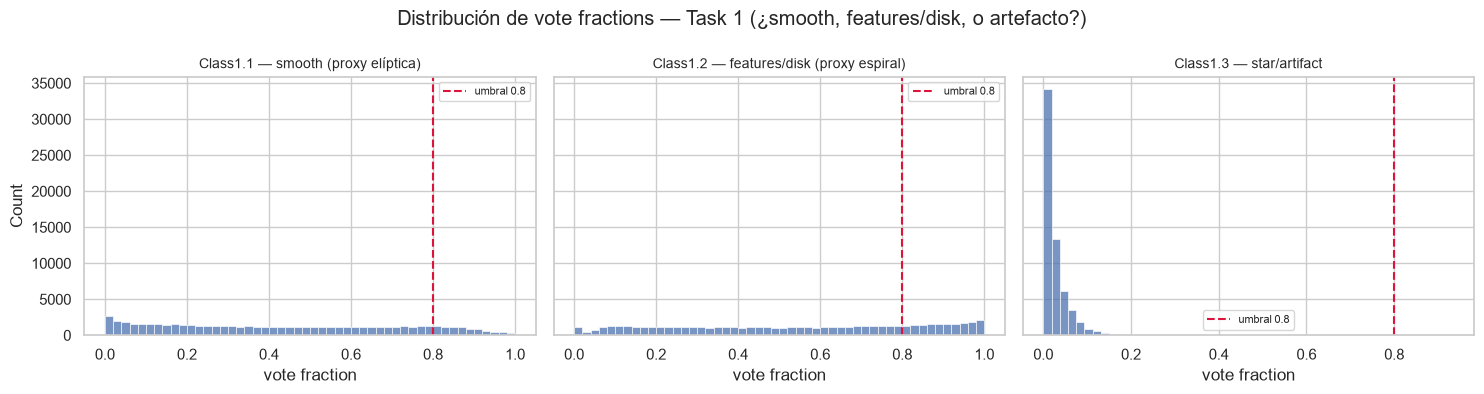

Suma Class1.1+1.2+1.3 - estadisticos (deberia ser ~1.0):
count    6.157800e+04
mean     1.000000e+00
std      4.085684e-07
min      9.999990e-01
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000001e+00
dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
cols = ['Class1.1', 'Class1.2', 'Class1.3']
titles = ['Class1.1 — smooth (proxy elíptica)', 'Class1.2 — features/disk (proxy espiral)', 'Class1.3 — star/artifact']

for ax, col, title in zip(axes, cols, titles):
    sns.histplot(df[col], bins=50, ax=ax, color='#4C72B0')
    ax.axvline(CLEAN_LABEL_THRESHOLD, color='crimson', linestyle='--', label=f'umbral {CLEAN_LABEL_THRESHOLD}')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('vote fraction')
    ax.legend(fontsize=8)

plt.suptitle('Distribución de vote fractions — Task 1 (¿smooth, features/disk, o artefacto?)')
plt.tight_layout()
plt.show()

print("Suma Class1.1+1.2+1.3 - estadisticos (deberia ser ~1.0):")
print((df['Class1.1'] + df['Class1.2'] + df['Class1.3']).describe())

**Lectura de los histogramas:**
- `Class1.3` (estrella/artefacto) está casi toda concentrada en 0: la gran mayoría de los objetos del dataset son galaxias reales, tal como se espera de un dataset ya pre-filtrado por Galaxy Zoo/SDSS.
- `Class1.1` y `Class1.2` muestran una distribución bimodal con masa importante en los extremos (cerca de 0 y cerca de 1), pero también una zona intermedia no despreciable — son los casos de bajo consenso entre voluntarios que el criterio de umbral 0.8 va a descartar explícitamente en la siguiente sección.

## Etiquetado binario (elíptica vs. espiral) con umbral de vote fraction confiable

Regla (`src/data/labeling.py`):

```
elíptica  si Class1.1 >= 0.8
espiral   si Class1.2 >= 0.8
descartar el resto (ambiguas, artefactos, bajo consenso)
```


In [8]:
df = derive_binary_label(df, threshold=CLEAN_LABEL_THRESHOLD)

counts = df['label'].value_counts()
n_total = len(df)
n_discarded = (df['label'] == AMBIGUOUS_LABEL).sum()

print(counts)
print()
for label, n in counts.items():
    print(f"{label:45s} {n:6d}  ({n / n_total:.1%} del total)")


label
ambigua       37305
spiral        16141
elliptical     8132
Name: count, dtype: int64

ambigua                                        37305  (60.6% del total)
spiral                                         16141  (26.2% del total)
elliptical                                      8132  (13.2% del total)


**diseño documentada:** con el umbral de 0.8, se descarta una fracción no trivial
del dataset (ver conteo arriba) — principalmente galaxias de bajo consenso entre voluntarios,
lenticulares ambiguas, y algunos artefactos. Es una decisión consciente que reduce el tamaño del
dataset a cambio de etiquetas de mayor confianza, siguiendo el mismo criterio que Walmsley et al. (2022)
y consistente con el subconjunto de alto acuerdo que reporta Dieleman et al. (2015).

## Balance de clases resultante (subconjunto limpio)

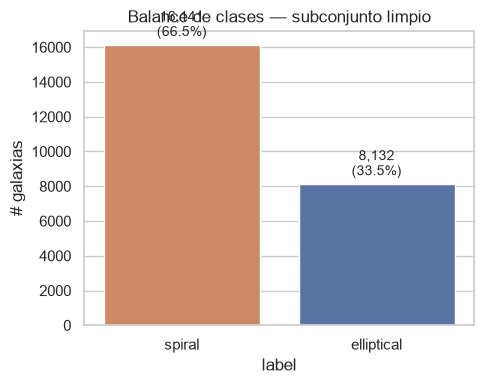

Total subconjunto limpio: 24,273 (39.4% del CSV original)
Ratio de desbalance (clase mayoritaria / minoritaria): 1.98x


In [9]:
df_clean = df[df['label'].isin([ELLIPTICAL_LABEL, SPIRAL_LABEL])].reset_index(drop=True)

class_counts = df_clean['label'].value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index,
            palette=['#DD8452', '#4C72B0'], legend=False, ax=ax)
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 500, f"{v:,}\n({v/len(df_clean):.1%})", ha='center', fontsize=10)
ax.set_ylabel('# galaxias')
ax.set_title('Balance de clases — subconjunto limpio')
plt.tight_layout()
plt.show()

print(f"Total subconjunto limpio: {len(df_clean):,} ({len(df_clean)/n_total:.1%} del CSV original)")
print(f"Ratio de desbalance (clase mayoritaria / minoritaria): {imbalance_ratio:.2f}x")

**Conclusión sobre el desbalance:** tal como advierte `README.md` (sección Manejo de desbalance de
clases), el subconjunto limpio **no está perfectamente balanceado**. El ratio de desbalance (ver
celda anterior) es moderado — no es un desbalance extremo tipo 1:100, pero es suficiente para
justificar aplicar `class_weight` en la función de pérdida y usar un split **estratificado**, tal
como recomienda el proyecto, en vez de asumir que un accuracy alto por sí solo es una buena señal.

## Muestras de imágenes por clase (inspección visual cualitativa)

Se incluyen también ejemplos de la clase `ambigua` (las galaxias descartadas del subconjunto
limpio porque ni `Class1.1` ni `Class1.2` alcanzan el umbral de 0.8) para inspeccionar
visualmente por qué el criterio de vote fraction confiable las deja fuera.

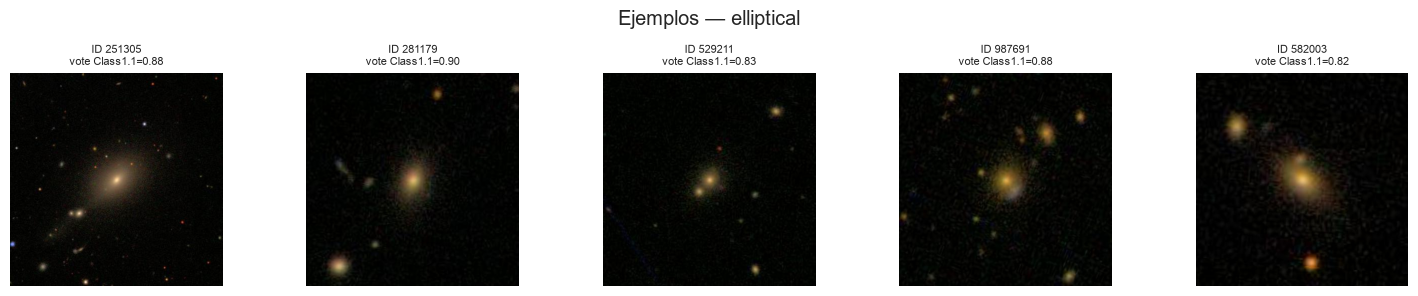

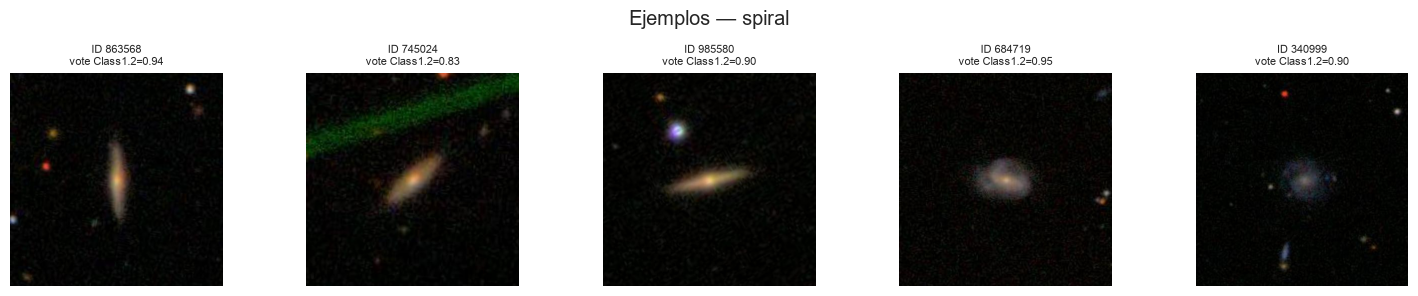

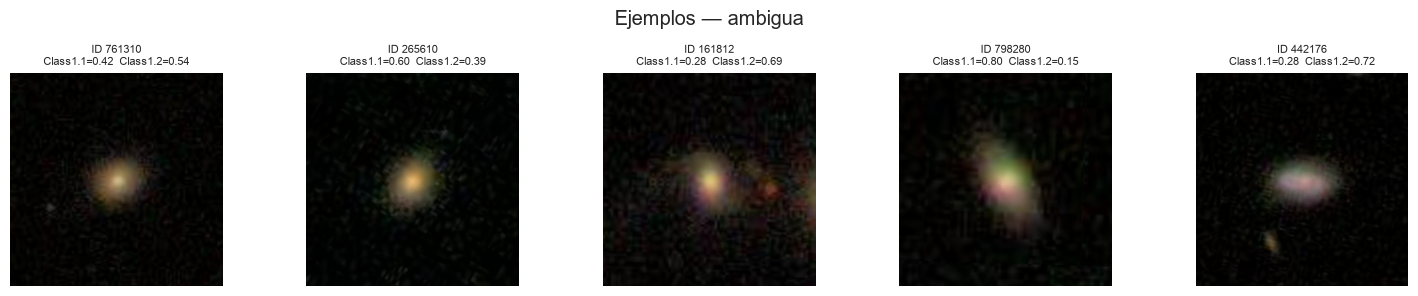

In [10]:
def show_class_grid(data, label, n=5, seed=RANDOM_SEED):
    sample = data[data['label'] == label].sample(n=n, random_state=seed)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    for ax, (_, row) in zip(axes, sample.iterrows()):
        img_path = TRAIN_IMAGES_DIR / f"{row['GalaxyID']}.jpg"
        img = Image.open(img_path)
        ax.imshow(img)
        if label == ELLIPTICAL_LABEL:
            vote_str = f"vote Class1.1={row['Class1.1']:.2f}"
        elif label == SPIRAL_LABEL:
            vote_str = f"vote Class1.2={row['Class1.2']:.2f}"
        else:
            vote_str = f"Class1.1={row['Class1.1']:.2f}  Class1.2={row['Class1.2']:.2f}"
        ax.set_title(f"ID {row['GalaxyID']}\n{vote_str}", fontsize=8)
        ax.axis('off')
    fig.suptitle(f"Ejemplos — {label}")
    plt.tight_layout()
    plt.show()

show_class_grid(df, ELLIPTICAL_LABEL)
show_class_grid(df, SPIRAL_LABEL)
show_class_grid(df, AMBIGUOUS_LABEL)

**Nota cualitativa:** las elípticas se ven como manchas suaves, redondeadas, sin estructura
interna visible; las espirales muestran brazos/disco claramente diferenciados. Esto es consistente
con que Task 1 (smooth vs. features/disk) sea el problema "fácil" del campo: Barchi et al. (2020)
reportan ~99% de accuracy en este binario elíptica-vs-espiral, frente a ~82% en un esquema de 3
clases sobre el mismo tipo de datos (ver `README.md`, sección Literatura de referencia) — la
separación visual es bastante nítida a simple vista en estos ejemplos de alto consenso.

Los ejemplos de la clase `ambigua` muestran el porqué del umbral: suelen ser galaxias con disco
tenue sobre un bulbo prominente (candidatas a lenticular), objetos pequeños/de bajo brillo donde es
difícil apreciar estructura, o casos donde el voto quedó repartido entre "smooth" y "features/disk"
sin que ninguna opción alcance el 80% de consenso.

## Estadísticas de las imágenes (tamaño, canales, rango de píxeles, calidad)

Cargar las 61,578 imágenes de entrenamiento una por una es costoso; para esta exploración inicial
se usa una muestra aleatoria representativa (con semilla fija) en vez de escanear el dataset completo.

In [11]:
SAMPLE_SIZE = 500
sample_ids = df_clean['GalaxyID'].sample(n=SAMPLE_SIZE, random_state=RANDOM_SEED).tolist()

records = []
corrupt = []
for gid in sample_ids:
    path = TRAIN_IMAGES_DIR / f"{gid}.jpg"
    try:
        with Image.open(path) as img:
            arr = np.asarray(img)
            records.append({
                'GalaxyID': gid,
                'width': img.width,
                'height': img.height,
                'mode': img.mode,
                'min_pixel': arr.min(),
                'max_pixel': arr.max(),
                'mean_pixel': arr.mean(),
            })
    except Exception as e:
        corrupt.append((gid, str(e)))

img_stats = pd.DataFrame(records)
print(f"Imagenes inspeccionadas: {len(img_stats)} / {SAMPLE_SIZE}")
print(f"Imagenes corruptas/no abribles: {len(corrupt)}")
img_stats.describe()

Imagenes inspeccionadas: 500 / 500
Imagenes corruptas/no abribles: 0


,GalaxyID,width,height,min_pixel,max_pixel,mean_pixel
count,500.000000,500.0,500.0,500.0,500.000000,500.000000
mean,553504.234000,424.0,424.0,0.0,229.030000,9.733607
std,255136.088564,0.0,0.0,0.0,26.924244,4.594573
min,101997.000000,424.0,424.0,0.0,136.000000,2.551705
25%,326234.000000,424.0,424.0,0.0,214.000000,7.321202
50%,548726.500000,424.0,424.0,0.0,234.000000,8.875874
75%,765558.750000,424.0,424.0,0.0,255.000000,10.806238
max,995869.000000,424.0,424.0,0.0,255.000000,71.229098


In [12]:
print("Tamanos unicos (width x height):", img_stats[['width', 'height']].drop_duplicates().values.tolist())
print("Modos de color unicos:", img_stats['mode'].unique().tolist())
print(f"Rango de pixeles observado: [{img_stats['min_pixel'].min()}, {img_stats['max_pixel'].max()}]")

Tamanos unicos (width x height): [[424, 424]]
Modos de color unicos: ['RGB']
Rango de pixeles observado: [0, 255]


**Notas:**
- Todas las imágenes de la muestra son de **424×424 px, RGB (`mode=RGB`)**, tal como se documenta en `README.md` — no se detectaron tamaños ni modos de color atípicos en esta muestra.
- El rango de píxeles es el esperado para JPG de 8 bits (`[0, 255]`); la normalización a `[0, 1]` o al esquema del backbone preentrenado queda pendiente para el pipeline de preprocesamiento (`src/data/dataset.py`), no para este notebook exploratorio.
- No se detectaron imágenes corruptas en la muestra. Un escaneo exhaustivo de las 61,578 imágenes queda como tarea posible pero no bloqueante para avanzar (costo computacional alto para el beneficio esperado, dado que el dataset ya viene curado por Kaggle/SDSS).

## Split train/val/test estratificado (subconjunto limpio)

Split a nivel de `GalaxyID`, estratificado por `label`, **antes** de cualquier data augmentation. Las proporciones objetivo están en `src/config.py`.

In [13]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_clean,
    test_size=(VAL_FRAC + TEST_FRAC),
    stratify=df_clean['label'],
    random_state=RANDOM_SEED,
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
    stratify=temp_df['label'],
    random_state=RANDOM_SEED,
)

for name, split in [('train', train_df), ('val', val_df), ('test', test_df)]:
    props = split['label'].value_counts(normalize=True)
    print(f"{name:6s} n={len(split):6d}  elliptical={props.get('elliptical', 0):.1%}  spiral={props.get('spiral', 0):.1%}")

print(f"\nTotal: {len(train_df) + len(val_df) + len(test_df)} (== {len(df_clean)} del subconjunto limpio)")

train  n= 16991  elliptical=33.5%  spiral=66.5%
val    n=  3641  elliptical=33.5%  spiral=66.5%
test   n=  3641  elliptical=33.5%  spiral=66.5%

Total: 24273 (== 24273 del subconjunto limpio)


Las proporciones de clase se preservan en los tres splits (diferencia de fracciones de punto
porcentual, no de puntos enteros), confirmando que el split estratificado funcionó como se espera.
Este split (o su lógica, migrada a `src/`) es el que debe alimentar el script de entrenamiento —
no se reimplementa dos veces.

## Conclusiones

**Decisiones tomadas en esta exploración:**
1. Etiquetado binario derivado de `Class1.1`/`Class1.2` con umbral de vote fraction confiable = 0.8 (ver sección 3 para el conteo exacto de galaxias descartadas).
2. El subconjunto limpio resultante presenta un desbalance moderado entre elíptica y espiral (ver ratio en sección 4) → se debe aplicar `class_weight` en el entrenamiento y mantener el split estratificado.
3. Las imágenes son consistentemente 424×424 RGB, sin corrupción detectada en la muestra inspeccionada.
4. Split train/val/test estratificado (70/15/15) a nivel de `GalaxyID`, hecho sobre el subconjunto limpio y antes de cualquier augmentation.


**Autor:** Alexander Carreño Correa

**Github:** [AlexanderCarreno](https://github.com/AlexanderCarreno)

**Linkedin:** [Alexander Carreño](https://www.linkedin.com/in/alexander-carreno)


<!-- Autor: Alexander Carreño Correa (alexandercorreacorrea1997@gmail.com) -->
